# The Inverted Pendulum

**Seong Cho** · ACME Volume 4, Lab 21

**Lab objective:** We will set up the LQR optimal control problem for the inverted pendulum and compute the solution numerically.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
from scipy.optimize import root
from scipy.linalg import solve_continuous_are
from scipy.integrate import odeint
from matplotlib import pyplot as plt

## The Simple Pendulum

A pendulum has a stable rest point directly below the pivot and an unstable one directly above. The inverted pendulum problem is to guide the bob toward the unstable fixed point and keep it balanced there; it is a classical test problem in dynamics and control theory, with applications such as guiding rockets and missiles.

For a bob of mass $m$ on a massless rod of length $l$, with angular displacement $\theta(t)$ from the stable equilibrium, Hamilton's Principle says the path minimizes

$$J[\theta] = \int_{t_0}^{t_1} L, \tag{21.1}$$

where the Lagrangian $L = T - U$ is the difference between the kinetic and potential energies. The kinetic energy is

$$T = \frac{m}{2}(\dot{x}^2 + \dot{y}^2) = \frac{ml^2\dot{\theta}^2}{2}, \tag{21.2}$$

the potential energy is $U = mg(l - l\cos\theta)$, and the Euler-Lagrange equation gives

$$0 = L_\theta - \frac{d}{dt}L_{\dot{\theta}} = -mgl\sin\theta - ml^2\ddot{\theta} \quad\Longrightarrow\quad \ddot{\theta} + \frac{g}{l}\sin\theta = 0. \tag{21.3}$$

Since energy is conserved, $\theta = 0$ is only Lyapunov stable; with friction and air drag it becomes asymptotically stable.

## The Inverted Pendulum: the control system

A gift of mass $m$ is suspended above a rickshaw of mass $M > m$ by a massless rod of length $l$; $\theta$ is the angle between the gift and its unstable equilibrium (clockwise), and a force $F$ moves the rickshaw along the $x$-axis. The path $(x, \theta)$ minimizes

$$J[x, \theta] = \int_{t_0}^{t_1} L. \tag{21.4}$$

With the rickshaw at $(x(t), 0)$ and the present at $(x - l\sin\theta, l\cos\theta)$, the kinetic energy is

$$T = \frac{1}{2}M\dot{x}^2 + \frac{1}{2}m\left((\dot{x} - l\dot{\theta}\cos\theta)^2 + (-l\dot{\theta}\sin\theta)^2\right) = \frac{1}{2}(M + m)\dot{x}^2 + \frac{1}{2}ml^2\dot{\theta}^2 - ml\dot{x}\dot{\theta}\cos\theta, \tag{21.5}$$

and the potential energy is $U = mgl\cos\theta$. By D'Alembert's Principle the nonconservative force $F$ enters the Euler-Lagrange equations on the right side:

$$\frac{\partial L}{\partial x} - \frac{d}{dt}\frac{\partial L}{\partial\dot{x}} = F, \qquad \frac{\partial L}{\partial\theta} - \frac{d}{dt}\frac{\partial L}{\partial\dot{\theta}} = 0. \tag{21.6}$$

Expanding,

$$F = (M + m)\ddot{x} - ml\ddot{\theta}\cos\theta + ml\dot{\theta}^2\sin\theta, \qquad l\ddot{\theta} = g\sin\theta + \ddot{x}\cos\theta. \tag{21.7}$$

If $\theta$ starts close to 0 we may assume $F$ keeps it small, and linearizing (21.7) about $(\theta, \dot{\theta}) = (0, 0)$ gives $F = (M + m)\ddot{x} - ml\ddot{\theta}$ and $l\ddot{\theta} = g\theta + \ddot{x}$, or

$$\ddot{x} = \frac{1}{M}F - \frac{m}{M}g\theta, \qquad \ddot{\theta} = \frac{1}{Ml}F + \frac{g}{Ml}(M + m)\theta. \tag{21.8}$$

With $x_1 = x$, $x_2 = x_1'$, $\theta_1 = \theta$, $\theta_2 = \theta_1'$ and the control $u = F$, this is the first order system

$$\begin{bmatrix} x_1 \\ x_2 \\ \theta_1 \\ \theta_2 \end{bmatrix}' = \begin{bmatrix} 0 & 1 & 0 & 0 \\ 0 & 0 & \frac{mg}{M} & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & \frac{g}{Ml}(M + m) & 0 \end{bmatrix}\begin{bmatrix} x_1 \\ x_2 \\ \theta_1 \\ \theta_2 \end{bmatrix} + u\begin{bmatrix} 0 \\ \frac{1}{M} \\ 0 \\ \frac{1}{Ml} \end{bmatrix},$$

or $z' = Az + Bu$.

## The infinite time horizon LQR problem

The cost function is

$$J[z] = \int_0^\infty (q_1x_1^2 + q_2x_2^2 + q_3\theta_1^2 + q_4\theta_2^2 + ru^2)\, dt = \int_0^\infty z^TQz + u^TRu\, dt, \tag{21.9}$$

with nonnegative weights, $Q = \operatorname{diag}(q_1, q_2, q_3, q_4)$ and $R = [\,r\,]$.

## Problem 1: The linearized system

> **Problem 1.** Write a function that returns the matrices $A$, $B$, $Q$, and $R$ given above. Let $g = 9.8\ \text{m/s}^2$.

In [2]:
def linearized_init(M, m, l, q1, q2, q3, q4, r):
    '''
    Parameters:
    5
    ----------
    M, m: floats
          masses of the rickshaw and the present
    l : float
        length of the rod
    q1, q2, q3, q4, r : floats
                        relative weights of the position and velocity of the rickshaw,
                        the angular displacement theta and the change in theta, and 
                        the control
    Return
    -------
    A : ndarray of shape (4,4)
    B : ndarray of shape (4,1)
    Q : ndarray of shape (4,4)
    R : ndarray of shape (1,1)
    '''
    g = 9.8
    A = np.array([[0, 1, 0, 0],
                  [0, 0, m*g/M, 0],
                  [0, 0, 0, 1],
                  [0, 0, (g/(M*l))*(M + m), 0]])
    B = np.array([0, 1/M, 0, 1/(M*l)])
    Q = np.diag([q1, q2, q3, q4])
    R = np.array([r])
    return A, B, Q, R

In [3]:
linearized_init(1, 1, 1, 1, 1, 1, 1, 1)

(array([[ 0. ,  1. ,  0. ,  0. ],
        [ 0. ,  0. ,  9.8,  0. ],
        [ 0. ,  0. ,  0. ,  1. ],
        [ 0. ,  0. , 19.6,  0. ]]),
 array([0., 1., 0., 1.]),
 array([[1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        [0, 0, 0, 1]]),
 array([1]))

## The algebraic Riccati equation

The optimal control problem (21.9) is a *Linear Quadratic Regulator* (LQR), whose optimal control is the linear state feedback law $\tilde{u} = -R^{-1}B^TP\tilde{z}$, where $P$ satisfies the Riccati differential equation $\dot{P}(t) = PA + A^TP + Q - PBR^{-1}B^TP$. With an infinite time horizon $\dot{P} = 0$, so $P$ is a constant matrix solving the *algebraic Riccati equation* (ARE)

$$PA + A^TP + Q - PBR^{-1}B^TP = 0. \tag{21.10}$$

The optimal state then evolves by

$$\dot{\tilde{z}} = (A - BR^{-1}B^TP)\tilde{z}. \tag{21.11}$$

## Problem 2: Solving the Riccati equation

> **Problem 2.** Write the following function to find the matrix $P$. Use `scipy.optimize.root`. Since `root` takes in a vector and not a matrix, you will have to reshape the matrix $P$ before passing it in and after getting your result, using `np.reshape(16)` and `np.reshape((4,4))`.
>
> Using the values $M = 23$, $m = 5$, $l = 4$, $q_1 = q_2 = q_3 = q_4 = 1$, $r = 10$, compute the eigenvalues of $A - BR^{-1}B^{T}P$. Are any of the eigenvalues positive? Consider differential equation (21.11) governing the optimal state $\tilde{z}$. Using this value of $P$, will we necessarily have $\tilde{z} \rightarrow 0$?

In [4]:
def find_P(A, B, Q, R):
    '''
    Parameters:
    ----------
    A, Q : ndarrays of shape (4,4)
    B : ndarray of shape (4,1)
    R : ndarray of shape (1,1)
    Returns
    -------
    P : the matrix solution of the Riccati equation
    '''
    r = R[0]
    def _P(P):
        P = P.reshape((4,4))
        out = P@A + A.T@P + Q - (1/r)*P@np.outer(B,B)@P
        return out.flatten()
    sol = root(_P, np.ones(16))['x']
    return sol.reshape((4,4))
    

In [5]:
M, m = 23., 5.
l = 4.
q1, q2, q3, q4 = 1., 1., 1., 1.
r = 10.
A, B, Q, R = linearized_init(M, m, l, q1, q2, q3, q4, r)
P = find_P(A, B, Q, R)
P

array([[  13.34929839,   88.60188369,   -8.52977855,  -63.47799003],
       [  88.60188369, 1181.90259733,  -50.38856895, -843.90508757],
       [  -8.52977855,  -50.38856895, -863.87628017,   35.87856103],
       [ -63.47799003, -843.90508757,   35.87856103,  894.05576091]])

In [6]:
r = R[0]
out = P@A + A.T@P + Q - (1/r)*P@np.outer(B,B)@P
np.allclose(out, np.zeros((4,4)))

True

In [7]:
H = A - (1/r)*np.outer(B,B)@P
np.linalg.eigvals(H)

array([-1.72875212+0.j        , -0.07538846+0.07490226j,
       -0.07538846-0.07490226j,  1.72530814+0.j        ])

$A - BR^{-1}B^TP$ has a positive eigenvalue, which implies that as $t \rightarrow \infty$, $\tilde{z}$ will drive off towards the eigenvector associated with the positive engenvalue.

> **Note.** We have no information on how many solutions (21.10) possesses; in general there may be many. We hope to find a unique solution $P$ that is *stabilizing*: the eigenvalues of $A - BR^{-1}B^TP$ have negative real part. To find this $P$, use `solve_continuous_are` from `scipy.linalg`, which is designed to solve the continuous algebraic Riccati equation.

In [8]:
P = solve_continuous_are(A, B.reshape((4,1)), Q, R)

In [9]:
r = R[0]
out = P@A + A.T@P + Q - (1/r)*P@np.outer(B,B)@P
np.allclose(out, np.zeros((4,4)), atol=1e-5)

True

In [10]:
H = A - (1/r)*np.outer(B,B)@P
np.linalg.eigvals(H)

array([-1.72875212+0.j        , -1.72530814+0.j        ,
       -0.07538846+0.07490226j, -0.07538846-0.07490226j])

Using Scipy's solve_continuous_are, we find that this P doesn't contain any positive eigenvalues, which implies that $\tilde{z} \rightarrow 0$ as $t \rightarrow \infty$

## Problem 3: The LQR solution

> **Problem 3.** Write the following function that implements the LQR solution described earlier. For the IVP solver, you can use your own or you may use the function `odeint` from `scipy.integrate`.

In [11]:
def rickshaw(tv, X0, A, B, Q, R, P):
    '''
    Parameters:
    ----------
    tv : ndarray of time values, with shape (n+1,)
    X0 : Initial conditions on state variables
    A, Q: ndarrays of shape (4,4)
    B : ndarray of shape (4,1)
    R : ndarray of shape (1,1)
    P : ndarray of shape (4,4)
    Returns
    -------
    Z : ndarray of shape (n+1,4), the state vector at each time
    U : ndarray of shape (n+1,), the control values
    '''
    r = R[0]
    H = A - (1/r)*np.outer(B,B)@P
    def _Z(y, t):
        dydt = H@y
        return dydt
    Z = odeint(_Z, X0, tv)
    U = -(1/r)*(B@P)@Z.T
    return Z, U
    

## Problem 4: Testing the controller

> **Problem 4.** Test the function made in Problem (3) with the following inputs:
>
> $M, m = 23, 5$
>
> $l = 4$
>
> $q_1 = q_2 = q_3 = q_4 = 1$
>
> $r = 10$
>
> $t_f = \text{None}$
>
> $X_0 = [-1, -1, .1, -.2]$
>
> Find the matrix $P$ using the `scipy.optimize.root` method with $t_f = 6$ as well as the `solve_continuous_are` method with $t_f = 60$. Plot the solutions $\tilde{z}$ and $\tilde{u}$. Compare your results as shown in Figure 21.3.

In [12]:
M, m = 23., 5.
l = 4.
q1, q2, q3, q4 = 1., 1., 1., 1.
r = 10.
tf = 6
X0 = np.array([-1, -1, .1, -.2])
A, B, Q, R = linearized_init(M, m, l, q1, q2, q3, q4, r)
P = find_P(A, B, Q, R)
tv = np.linspace(0, tf, 101)
Z, U = rickshaw(tv, X0, A, B, Q, R, P)

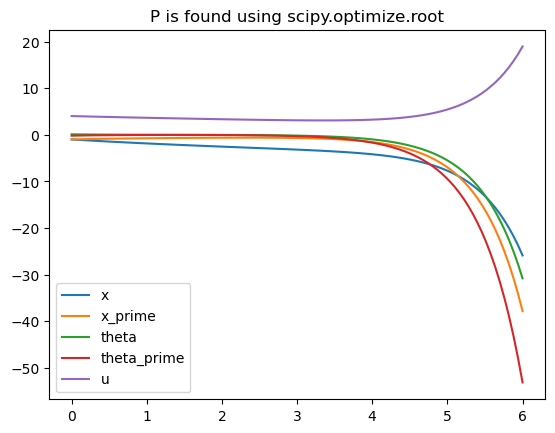

In [13]:
[x, x_p, t, t_p, u] = plt.plot(tv, np.column_stack([Z, U]))
plt.legend([x, x_p, t, t_p, u], ['x', 'x_prime', 'theta', 'theta_prime', 'u'])
plt.title("P is found using scipy.optimize.root")
plt.show()

In [14]:
M, m = 23., 5.
l = 4.
q1, q2, q3, q4 = 1., 1., 1., 1.
r = 10.
tf = 60
X0 = np.array([-1, -1, .1, -.2])
A, B, Q, R = linearized_init(M, m, l, q1, q2, q3, q4, r)
P = solve_continuous_are(A, B.reshape((4,1)), Q, R)
tv = np.linspace(0, tf, 101)
Z, U = rickshaw(tv, X0, A, B, Q, R, P)

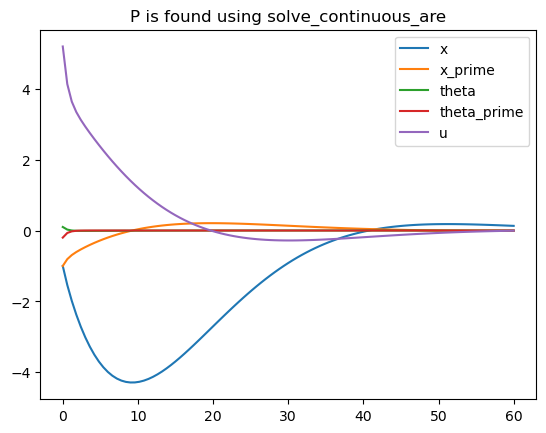

In [15]:
[x, x_p, t, t_p, u] = plt.plot(tv, np.column_stack([Z, U]))
plt.legend([x, x_p, t, t_p, u], ['x', 'x_prime', 'theta', 'theta_prime', 'u'])
plt.title("P is found using solve_continuous_are")
plt.show()

In [16]:
A = np.array([0.01])
B = np.array([-1])
Q = np.array([0])
R = np.array([1])
solve_continuous_are(A, B, Q, R)

array([[0.02]])